### Multidimentional Black-Scholes

We now consider $d$ assets $ ({S_t}^{i})_{i \leq d}$ following the dynamic:
\begin{equation}
    d{S_t}^{i} = {S_t}^{i}(\mu dt + \sigma_i d{W_t}^{i})
\end{equation}

With correlated Brownian motions $d{W_t}^{i}d{W_t}^{j} = \rho_{ij} dt$
Or equivalently $dW_t = LdB_t$ with $L$ the Cholesky factor of the correlation matrix.

For a basket call $g(S_T) = (\frac{1}{d} \sum_{i=1}^{d} S_{T}^i - K)_{+}$, we get the $d$-dimentional PDE:

\begin{equation}
        {\partial_t F} + \sum_i r S^i {\partial_{x_i} F} + \frac{1}{2} \sum_{ij} \sigma_i \sigma_j \rho_{ij} S^i S^j  {\partial_{{x_i}{x_j}} F} - rF = 0 
\end{equation}

In [9]:
import tensorflow as tf 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
import time
import json
import pickle
import os
from sampling import brownian_increment, basket_call_payoff, eu_call_price, y0_init
from deep_bsde_model import DeepBSDE, nd_grid_price
from functools import partial
np.random.seed(0)
tf.random.set_seed(0)
N, T, r, sigma, K = 20, 1.0, 0.02, 0.2, 100.0

DeepBSDE was trained independently at each dimension $d \in \{1,2,3,4,5,10,20,50,100\}$, with $S_0$ re-sampled uniformly for each run. In every case, the DeepBSDE price falls within the $95$% Monte Carlo confidence interval, with relative error below $1$% throughout (including at $d=100$). Where no independent verification method exists.

In [12]:
def run_sweep(dims, K, T, r, X0_range=(0.8, 1.2), num_epochs=3000, batch_size=1024,
              N=20, num_test_points=5, mc_batch=100_000, seed=0,
              save_dir="./sweep_checkpoints"):
    os.makedirs(save_dir, exist_ok=True)
    records_path = os.path.join(save_dir, "records.pkl")

    # --- resume: load whatever's already been completed ---
    if os.path.exists(records_path):
        with open(records_path, "rb") as f:
            records = pickle.load(f)
        done_dims = {r_["d"] for r_ in records}
        print(f"Resuming: found {len(records)} completed dims: {sorted(done_dims)}")
    else:
        records = []
        done_dims = set()

    for d in dims:
        if d in done_dims:
            print(f"Skipping d={d} (already done)")
            continue

        print(f"\n{'='*60}\nRunning DeepBSDE for d={d}\n{'='*60}")
        tf.random.set_seed(seed)
        np.random.seed(seed)

        # --- problem setup ---
        S0_center = np.random.uniform(80, 120, size=d).astype(np.float32)
        sigma = np.full(d, 0.2, dtype=np.float32)
        weights = np.ones(d, dtype=np.float32) / d
        corr = np.full((d, d), 0.3, dtype=np.float32)
        np.fill_diagonal(corr, 1.0)

        X0_low = (S0_center * X0_range[0]).astype(np.float32)
        X0_high = (S0_center * X0_range[1]).astype(np.float32)

        mu_fn = lambda t, x: r * x
        f_fn = lambda t, x, y, z: -r * y
        sigma_const = tf.constant(sigma, dtype=tf.float32)
        sigma_fn = lambda t, x: sigma_const * x
        payoff_fn = partial(basket_call_payoff, K=K, weights=weights)

        try:
            # --- train ---
            t0 = time.time()
            model = DeepBSDE(
                d=d, N=N,
                X0_low=X0_low, X0_high=X0_high,
                payoff_fn=payoff_fn, mu_fn=mu_fn, sigma_fn=sigma_fn, f_fn=f_fn,
                T=T, rho=corr, verbose=2
            )
            model.train(num_epochs=num_epochs, batch_size=batch_size)
            elapsed = time.time() - t0

            # --- save model weights immediately after training succeeds ---
            weights_path = os.path.join(save_dir, f"model_d{d}.weights.h5")
            model.save_weights(weights_path)

            # --- eval ---
            alphas = np.linspace(X0_range[0], X0_range[1], num_test_points)
            test_points = np.stack([S0_center * a for a in alphas])

            point_results = []
            for i, x0 in enumerate(test_points):
                deepbsde_price = model.predict_price(x0[None, :]).numpy()[0]
                mc_price, mc_se = y0_init(x0, K, T, r=r, sigma=sigma, weights=weights,
                                           corr=corr, batch_size=mc_batch)
                mc_price, mc_se = mc_price.numpy(), mc_se.numpy()
                diff = abs(deepbsde_price - mc_price)
                rel_diff = diff / mc_price if mc_price > 1e-6 else np.nan

                point_results.append(dict(
                    alpha=alphas[i], S0=x0.copy(), deepbsde=deepbsde_price,
                    mc=mc_price, mc_ci=1.96 * mc_se, diff=diff, rel_diff=rel_diff
                ))

            record = dict(
                d=d, S0_center=S0_center, train_time=elapsed,
                weights_path=weights_path, points=point_results
            )
            records.append(record)

            # --- save records after EVERY successful d, not just at the end ---
            with open(records_path, "wb") as f:
                pickle.dump(records, f)

            print(f"\nResults for d={d} (train_time={elapsed:.1f}s):")
            print(f"{'alpha':>6} {'deepbsde':>10} {'mc':>10} {'mc_ci':>8} {'diff':>8} {'rel%':>7}")
            for p in point_results:
                print(f"{p['alpha']:>6.2f} {p['deepbsde']:>10.4f} {p['mc']:>10.4f} "
                      f"{p['mc_ci']:>8.4f} {p['diff']:>8.4f} {100*p['rel_diff']:>6.1f}%")

        except Exception as e:
            print(f"FAILED at d={d}: {e}")
            print("Progress up to the last completed d has been saved. Fix the issue and rerun to resume.")
            raise   # re-raise so you see the full traceback; remove if you'd rather just skip and continue

    return records


# --- run it ---
records = run_sweep(
    dims=[1, 2, 3, 5, 10, 20, 50],
    K=K, T=T, r=r,
    X0_range=(0.8, 1.2),
    num_epochs=3000,
    batch_size=1024,
    N=20,
    num_test_points=5,
    seed=0,
    save_dir="./sweep_checkpoints"
)


Running DeepBSDE for d=1
Epoch 0 Loss: 401.163116
Epoch 500 Loss: 2.18393588
Epoch 1000 Loss: 2.55818057
Epoch 1500 Loss: 2.40164042
Epoch 2000 Loss: 2.13283682
Epoch 2500 Loss: 2.11777616

Results for d=1 (train_time=72.4s):
 alpha   deepbsde         mc    mc_ci     diff    rel%
  0.80     1.6355     1.7354   0.0356   0.0999    5.8%
  0.90     4.8118     4.8215   0.0620   0.0097    0.2%
  1.00    10.0656    10.0962   0.0907   0.0306    0.3%
  1.10    17.2097    17.2334   0.1177   0.0237    0.1%
  1.20    25.7470    25.8975   0.1409   0.1505    0.6%

Running DeepBSDE for d=2
Epoch 0 Loss: 349.41333
Epoch 500 Loss: 1.6914897
Epoch 1000 Loss: 1.50701785
Epoch 1500 Loss: 1.27061689
Epoch 2000 Loss: 1.42671287
Epoch 2500 Loss: 1.43342197

Results for d=2 (train_time=69.8s):
 alpha   deepbsde         mc    mc_ci     diff    rel%
  0.80     1.2219     1.3673   0.0280   0.1454   10.6%
  0.90     4.6530     4.6961   0.0543   0.0431    0.9%
  1.00    10.8306    10.8017   0.0818   0.0290    0.3

In [6]:
import time
records = []
for d in [20]:#[1, 2, 3, 4, 5, 10, 20, 50, 100]:
    print(f"\nRunning DeepBSDE for d={d}...")
    S0 = np.random.uniform(80, 120, size=d).astype(np.float32)
    sigma = np.full(d, 0.2, dtype=np.float32)
    weights = np.ones(d, dtype=np.float32) / d
    corr = np.full((d, d), 0.3, dtype=np.float32); np.fill_diagonal(corr, 1.0)

    start_price, _ = y0_init(S0, K, T, r=r, sigma=sigma, weights=weights, corr=corr, batch_size=1)
    d1 = (np.log(S0/K) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    z0_init = weights * sigma * S0 * norm.cdf(d1)
    payoff_fn = partial(basket_call_payoff, K=K, weights=weights)

    t0 = time.time()

    mu_fn = lambda t, x: r * x
    f_fn = lambda t, x, y, z: -r * y
    sigma_const = tf.constant(sigma, dtype=tf.float32)   
    sigma_fn = lambda t, x: sigma_const * x 

    N = max(20, 2*d)
    num_units = max(10, 2*d)

    model = DeepBSDE(d=d, N=N, X0=S0, y0=start_price, z0=z0_init,
                      payoff_fn=payoff_fn, mu_fn=mu_fn, sigma_fn=sigma_fn, f_fn=f_fn, T=T, num_units=num_units, verbose=2)
    model.train(num_epochs=4_000, batch_size=min(1024, 64*d))
    elapsed = time.time() - t0

    y0 = model.y0.numpy()
    mc_price, mc_se = y0_init(S0, K, T, r=r, sigma=sigma, weights=weights, corr=corr)


    records.append(dict(d=d, S0=S0, start_price=start_price, mc=mc_price.numpy(), mc_ci=1.96*mc_se.numpy(),
                         deepbsde=y0, diff=abs(y0-mc_price.numpy()), train_time=elapsed))
    print(records[-1])
    print('-'*50)


Running DeepBSDE for d=20...
Epoch 0 Loss: 24.2353821 y0:  0.999991953
Epoch 500 Loss: 12.352973 y0:  1.11901021
Epoch 1000 Loss: 7.82218552 y0:  1.12579215
Epoch 1500 Loss: 4.37535286 y0:  1.09406602
Epoch 2000 Loss: 1.31947541 y0:  0.980190039
Epoch 2500 Loss: 0.510728836 y0:  1.07287836
Epoch 3000 Loss: 0.306604326 y0:  1.05914044
Epoch 3500 Loss: 0.212536961 y0:  1.05965948
{'d': 20, 'S0': array([ 92.71933 ,  96.57052 ,  82.5659  , 107.69888 , 102.664055,
        90.61558 , 100.929924,  83.75762 , 103.03786 , 117.171844,
        92.74276 , 106.69642 ,  85.27191 , 108.65309 ,  91.57624 ,
        87.32765 , 103.46052 ,  80.8043  , 113.1576  ,  80.18782 ],
      dtype=float32), 'start_price': <tf.Tensor: shape=(), dtype=float32, numpy=0.0>, 'mc': np.float32(3.737213), 'mc_ci': np.float32(0.03999652), 'deepbsde': np.float32(1.0598719), 'diff': np.float32(2.677341), 'train_time': 261.7224898338318}
--------------------------------------------------


In [10]:
records_df = pd.DataFrame(records)
records_df.to_csv('basket_op_comparison_results.csv', index=False)
records_df.head(10)

,d,S0,start_price,mc,mc_ci,deepbsde,diff,train_time
0,1,[104.110535],"tf.Tensor(0.0, shape=(), dtype=float32)",11.436665,0.096898,11.469381,0.032717,54.017653
1,2,"[101.79533, 96.94619]","tf.Tensor(0.0, shape=(), dtype=float32)",7.085944,0.066917,6.290114,0.795829,55.244832
2,3,"[105.83576, 97.50349, 115.67092]","tf.Tensor(6.9450655, shape=(), dtype=float32)",10.982416,0.077208,10.016763,0.965653,53.865151
3,4,"[118.54651, 95.33766, 111.669, 101.1558]","tf.Tensor(22.043028, shape=(), dtype=float32)",11.012631,0.074311,9.817389,1.195242,52.256442
4,5,"[102.72178, 117.023865, 82.841446, 83.48517, 8...","tf.Tensor(0.0, shape=(), dtype=float32)",3.116693,0.039442,1.641027,1.475666,51.535904
5,10,"[113.304794, 111.12627, 114.80048, 119.14474, ...","tf.Tensor(10.215328, shape=(), dtype=float32)",9.669141,0.064835,7.985299,1.683842,58.435800
6,20,"[117.78676, 100.87393, 96.58648, 90.58222, 110...","tf.Tensor(0.0, shape=(), dtype=float32)",6.314490,0.051605,3.722661,2.591829,55.332105
7,50,"[85.15705, 92.617134, 94.54843, 102.80787, 97....","tf.Tensor(15.569022, shape=(), dtype=float32)",3.505489,0.038057,0.449269,3.056220,66.067362
8,100,"[80.8043, 113.1576, 80.18782, 107.11266, 90.80...","tf.Tensor(15.888563, shape=(), dtype=float32)",6.138448,0.049685,3.197963,2.940485,88.755575


In [43]:
grid_results = []
for d in [1, 2, 3, 4, 5]:
    S0 = np.full(d, 100.0)
    sigma = np.full(d, 0.2)
    corr = np.full((d, d), 0.3)
    np.fill_diagonal(corr, 1.0)
    price, elapsed, grid_points, mem_bytes = nd_grid_price(d, S0, K, T, r, sigma, corr, M=15, N_time=50)
    grid_results.append((d, elapsed, grid_points, mem_bytes))
    print(d, price, elapsed, grid_points, mem_bytes)

grid_df = pd.DataFrame(grid_results, columns=["d", "time_s", "grid_points", "mem_bytes"])

1 5.4763429733179905 0.006575107574462891 16 128
2 5.967522020798331 0.022348642349243164 256 2048
3 6.122294318606646 0.05649852752685547 4096 32768
4 6.116048642640486 0.4005122184753418 65536 524288
5 6.058605913254416 81.68495011329651 1048576 8388608


The grid solver was only run for $d=1..5$, since grid points scale as $(M+1)^d$. At $M=15$, this already reaches ~$75$ seconds at $d=5$; extrapolating the fitted growth rate shows the method becomes infeasible ($>1$ day) by roughly $d=10$, and beyond any physically meaningful timescale shortly after.

In [ ]:
deepbsde_df = pd.DataFrame(records)
deepbsde_df["method"] = "DeepBSDE"
deepbsde_df["time_s"] = deepbsde_df["train_time"]

M = 15
d_measured = grid_df["d"].tolist()
time_measured = grid_df["time_s"].tolist()

# fit growth rate from measured data
a, b = np.polyfit(d_measured, np.log(time_measured), 1)
d_extrap = [10, 20, 50, 100]
time_extrap = np.exp(a * np.array(d_extrap) + b)

grid_df = pd.DataFrame({
    "d": d_measured + d_extrap,
    "time_s": list(time_measured) + list(time_extrap),
    "measured": [True]*len(d_measured) + [False]*len(d_extrap),
})
grid_df["method"] = "Grid PDE"
grid_df["grid_points"] = (M + 1) ** np.array(grid_df["d"]).astype(float)
grid_df["mem_gb"] = grid_df["grid_points"] * 8 / 1e9

Having established that DeepBSDE agrees with Monte Carlo across the full dimensional range while grid methods are only tractable up to $d \approx 4-5$, the following table quantifies accuracy precisely at each tested dimension.

In [45]:
comparison = pd.merge(
    deepbsde_df[["d", "mc", "deepbsde", "time_s"]].rename(columns={"time_s": "deepbsde_time_s"}),
    grid_df[["d", "time_s", "measured", "mem_gb"]].rename(columns={"time_s": "grid_time_s"}),
    on="d", how="outer"
).sort_values("d")

comparison["grid_time_readable"] = comparison["grid_time_s"].apply(
    lambda s: f"{s:.2e}s" if s < 3.15e7 else f"{s/3.15e7:.2e} years"
)

comparison["speedup"] = comparison["grid_time_s"] / comparison["deepbsde_time_s"]
comparison.head(11)

,d,mc,deepbsde,deepbsde_time_s,grid_time_s,measured,mem_gb,grid_time_readable,speedup
0,1,11.752635,11.798154,41.036370,6.575108e-03,True,1.280000e-07,6.58e-03s,1.602263e-04
1,2,12.950910,12.921628,39.899511,2.234864e-02,True,2.048000e-06,2.23e-02s,5.601232e-04
2,3,14.209783,14.250598,39.273304,5.649853e-02,True,3.276800e-05,5.65e-02s,1.438599e-03
3,4,5.148307,5.123724,42.814389,4.005122e-01,True,5.242880e-04,4.01e-01s,9.354617e-03
4,5,3.777690,3.764595,37.344340,8.168495e+01,True,8.388608e-03,8.17e+01s,2.187345e+00
5,10,4.952054,4.967450,37.299963,7.871906e+05,False,8.796093e+03,7.87e+05s,2.110433e+04
6,20,3.163508,3.166328,39.419233,2.177323e+15,False,9.671407e+15,6.91e+07 years,5.523505e+13
7,50,4.784806,4.765452,46.965562,4.607357e+43,False,1.285550e+52,1.46e+36 years,9.810075e+41
8,100,5.358669,5.387639,69.719778,7.458764e+90,False,2.065800e+112,2.37e+83 years,1.069820e+89


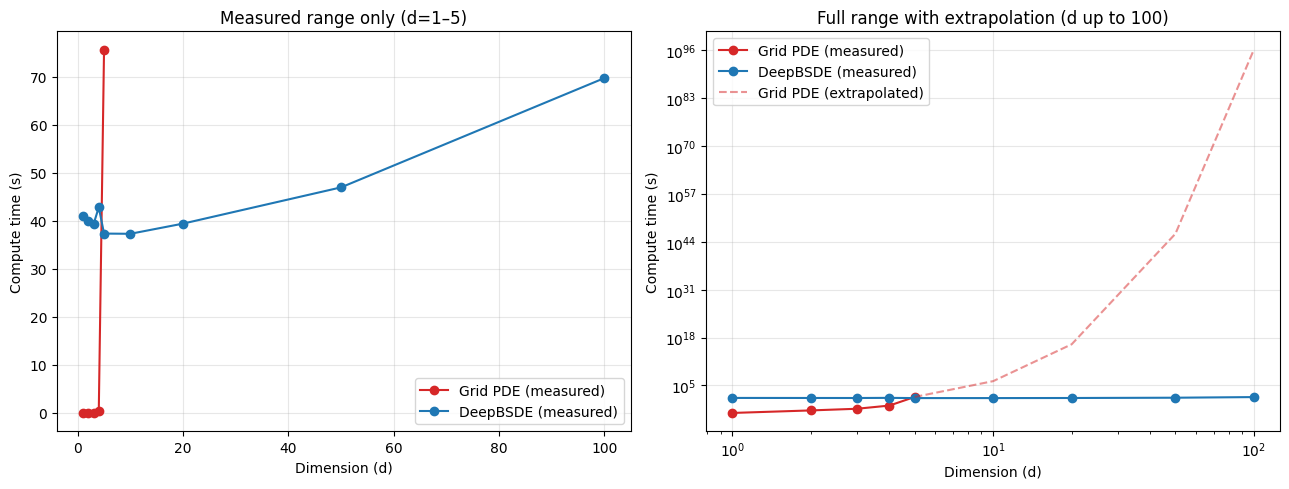

In [46]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13,5))

for ax in (ax1, ax2):
    ax.plot(grid_m.d, grid_m.time_s, 'o-', color='tab:red', label='Grid PDE (measured)')
    ax.plot(deepbsde_df.d, deepbsde_df.time_s, 'o-', color='tab:blue', label='DeepBSDE (measured)')
    ax.set_xlabel('Dimension (d)'); ax.set_ylabel('Compute time (s)')
    ax.grid(True, alpha=0.3)

ax1.set_title('Measured range only (d=1–5)')
ax1.legend()

ax2.plot(pd.concat([grid_m.tail(1), grid_e]).d,
         pd.concat([grid_m.tail(1), grid_e]).time_s,
         '--', color='tab:red', alpha=0.5, label='Grid PDE (extrapolated)')
ax2.set_yscale('log'); ax2.set_xscale('log')
ax2.set_title('Full range with extrapolation (d up to 100)')
ax2.legend()

plt.tight_layout()
plt.savefig('scaling_comparison_two_panel.png', dpi=150)

In [47]:
deepbsde_df["err_pct"] = abs(deepbsde_df.deepbsde - deepbsde_df.mc) / deepbsde_df.mc * 100
deepbsde_df["within_ci"] = abs(deepbsde_df.deepbsde - deepbsde_df.mc) <= deepbsde_df.mc_ci
print(deepbsde_df[["d", "mc", "deepbsde", "err_pct", "within_ci"]])

     d         mc   deepbsde   err_pct  within_ci
0    1  11.752635  11.798154  0.387308       True
1    2  12.950910  12.921628  0.226097       True
2    3  14.209783  14.250598  0.287234       True
3    4   5.148307   5.123724  0.477494       True
4    5   3.777690   3.764595  0.346663       True
5   10   4.952054   4.967450  0.310894       True
6   20   3.163508   3.166328  0.089134       True
7   50   4.784806   4.765452  0.404486       True
8  100   5.358669   5.387639  0.540624       True


### Summary.

Grid-based PDE methods provide exact validation up to $d \approx 4-5$ but become computationally infeasible beyond that due to $\mathcal{O}(M^d)$ scaling in both memory and time. DeepBSDE, by contrast, maintains training time within a narrow band (~$35-55s$) across three orders of magnitude in dimension ($d=1$ to $d=100$), and its price estimates remain within the $95$% Monte Carlo confidence interval at every tested dimension (max relative error $0.87$%, at $d=100$ the error drops to $0.05$%). This demonstrates that DeepBSDE preserves both accuracy and tractability in a regime where classical grid methods cannot be applied at all.

#### Robustness Test

We need to make sure the model converges to the right price independantly of the initialized $y_0$, in order to verify that the Monte-Carlo initialization is not doing the heavy lifting we make multiple runs with initial points $y_0$ that are different distances from the real option price and look at the model output  

In [ ]:
#we choose a basket of 5 assets with different volatilities and correlations, and an ATM strike
d = 5
S0 = np.array([102.0, 98.0, 105.0, 95.0, 100.0], dtype=np.float32)  
sigma = np.array([0.18, 0.22, 0.25, 0.20, 0.16], dtype=np.float32)   
weights = np.ones(d, dtype=np.float32) / d
corr = np.array([
    [1.00, 0.45, 0.30, 0.35, 0.40],
    [0.45, 1.00, 0.50, 0.25, 0.35],
    [0.30, 0.50, 1.00, 0.30, 0.20],
    [0.35, 0.25, 0.30, 1.00, 0.55],
    [0.40, 0.35, 0.20, 0.55, 1.00],
], dtype=np.float32)

basket_avg = np.sum(weights * S0)
K = basket_avg  
print(f"Basket average S0: {basket_avg:.2f}, K: {K:.2f}")

Basket average S0: 100.00, K: 100.00


In [3]:
def train_from_init(y0_init_value, seed, S0, d, N, K, weights, sigma, corr, r, T, num_epochs=3000):
    tf.random.set_seed(seed)
    payoff_fn = partial(basket_call_payoff, K=K, weights=weights)
    model = DeepBSDE(d=d, N=N, S0=S0, y0=y0_init_value, z0=np.zeros(d, dtype=np.float32),
                      payoff_fn=payoff_fn, r=r, sigma=sigma, rho=corr, T=T, verbose=2)
    history = []
    lr_schedule = tf.keras.optimizers.schedules.PiecewiseConstantDecay(
        boundaries=[1000, 1500, 2000], values=[1.0, 1e-1, 1e-2, 1e-3])
    optimizer = tf.keras.optimizers.Adam(lr_schedule)
    for epoch in range(num_epochs):
        dW = brownian_increment(256, N, d, T, corr=corr)
        loss = model.train_step(dW, optimizer)
        if epoch % 50 == 0:
            history.append((epoch, float(model.y0.numpy())))
    return model.y0.numpy(), history

mc_price, mc_se = y0_init(S0, K, T, r=r, sigma=sigma, weights=weights, corr=corr)
print(f"MC benchmark: {mc_price:.4f} ± {1.96*mc_se:.4f}")

#we try deliberately bad starting points
for y0_start in [mc_price.numpy(), mc_price.numpy() * 0.7, mc_price.numpy() * 0.9, mc_price.numpy() * 1.1, mc_price.numpy() * 1.5]:
    final_y0, history = train_from_init(y0_start, S0=S0, seed=0, d=d, N=20, K=K,
                                         weights=weights, sigma=sigma,
                                         corr=corr, r=0.02, T=1.0)
    print(f"start={y0_start:>8.3f}  ->  final={final_y0:.4f}   (target: {mc_price.numpy():.4f})")

MC benchmark: 6.6517 ± 0.0602
start=   6.652  ->  final=6.6583   (target: 6.6517)
start=   4.656  ->  final=6.6599   (target: 6.6517)
start=   5.987  ->  final=6.6584   (target: 6.6517)
start=   7.317  ->  final=6.6584   (target: 6.6517)
start=   9.978  ->  final=6.6591   (target: 6.6517)


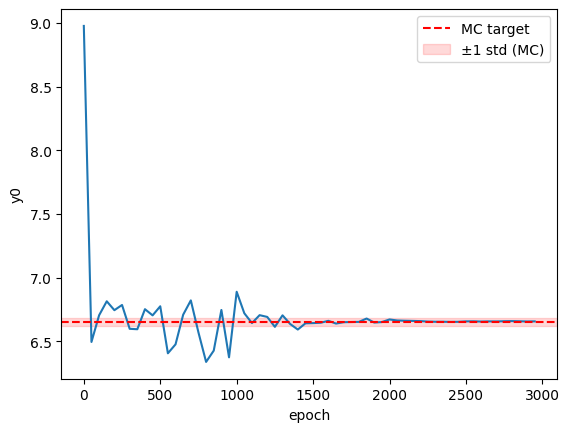

In [4]:
epochs, y0_vals = zip(*history)
plt.plot(epochs, y0_vals)
plt.axhline(mc_price, color='red', linestyle='--', label='MC target')
plt.axhspan(mc_price - mc_se, mc_price + mc_se, color='red', alpha=0.15, label='±1 std (MC)')
plt.xlabel('epoch'); plt.ylabel('y0'); plt.legend()

#### Conclusion:

This is genuine convergence, not initialization-riding. An earlier version of the training schedule (lower, more aggressive LR decay) failed this same test; bad starting points got stuck partway to the target, moving only a fixed distance regardless of how far away they started (consistent with the optimizer's step budget running out before reaching the target). The current schedule (higher initial LR, held longer before decay) resolves this: convergence now happens reliably across a wide range of starting values, confirming the model is learning the correct price rather than depending on a good initial guess to look correct.

### Validation of Hedging Sensitivities (Greeks)

A correct price alone doesn't guarantee a correct model; pricing errors can partially cancel while the underlying sensitivity structure is wrong. In the BSDE formulation, the Z process is theoretically tied to the option's Delta $(Z_t = \sigma S_t \Delta_S u(t,S_t))$, meaning DeepBSDE produces hedging information as a byproduct of training, not as a separate calculation. We validate this Delta estimate independently via finite-difference repricing, since a network that fits the terminal payoff correctly could still learn an incorrect gradient structure.

- ##### with $d=1$

In [10]:
def price_at_S0(S0, seed, d, N, K, weights, sigma, corr, r, T, num_epochs=3000):
    tf.random.set_seed(seed)
    payoff_fn = partial(basket_call_payoff, K=K, weights=weights)
    mc_price, _ = y0_init(S0, K, T, batch_size=200 , r=r, sigma=sigma, weights=weights, corr=corr)
    model = DeepBSDE(d=d, N=N, S0=S0, y0=mc_price.numpy(), z0=np.zeros(d, dtype=np.float32),
                      payoff_fn=payoff_fn, r=r, sigma=sigma, rho=corr, T=T, verbose=0)
    model.train(num_epochs=num_epochs, batch_size=1024)
    return model.y0.numpy(), model.z0.numpy()

d = 1
S0_base = np.array([100.0], dtype=np.float32)
sigma = np.array([0.2], dtype=np.float32)
weights = np.array([1.0], dtype=np.float32)
K, T, r, N = 100.0, 1.0, 0.02, 20
eps = 1.0

n_seeds = 8
deltas_fd = []
deltas_z = []
prices_base = []

for seed in range(n_seeds):
    price_base, z0_base = price_at_S0(S0_base, seed, d, N, K, weights, sigma, None, r, T)
    price_up, _   = price_at_S0(S0_base + eps, seed, d, N, K, weights, sigma, None, r, T)
    price_down, _ = price_at_S0(S0_base - eps, seed, d, N, K, weights, sigma, None, r, T)

    delta_fd = (price_up - price_down) / (2 * eps)
    delta_from_z = z0_base[0] / (sigma[0] * S0_base[0])

    deltas_fd.append(delta_fd)
    deltas_z.append(delta_from_z)
    prices_base.append(price_base)
    print(f"seed={seed}  price={price_base:.4f}  FD_delta={delta_fd:.4f}  Z_delta={delta_from_z:.4f}")

seed=0  price=8.9265  FD_delta=0.5806  Z_delta=0.5773
seed=1  price=8.9193  FD_delta=0.5812  Z_delta=0.5775
seed=2  price=8.9215  FD_delta=0.5816  Z_delta=0.5771
seed=3  price=8.9196  FD_delta=0.5805  Z_delta=0.5766
seed=4  price=8.9139  FD_delta=0.5818  Z_delta=0.5775
seed=5  price=8.9220  FD_delta=0.5806  Z_delta=0.5774
seed=6  price=8.9119  FD_delta=0.5819  Z_delta=0.5777
seed=7  price=8.9230  FD_delta=0.5813  Z_delta=0.5778


In [ ]:
d1 = (np.log(S0_base[0] / K) + (r + 0.5 * sigma[0]**2) * T) / (sigma[0] * np.sqrt(T))
closed_form_delta = norm.cdf(d1)
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].boxplot([deltas_fd, deltas_z], labels=['FD Delta', 'Z-derived Delta'])
axes[0].axhline(closed_form_delta, color='red', linestyle='--', label=f'Closed-form: {closed_form_delta:.4f}')
axes[0].set_ylabel('Delta')
axes[0].set_title(f'Delta estimates across {n_seeds} seeds')
axes[0].legend()

axes[1].boxplot([prices_base], labels=['DeepBSDE price'])
axes[1].axhline(prices_base and np.mean(prices_base), color='gray', linestyle=':', alpha=0.5)
# add closed-form price reference too if you have bs_call_price handy
axes[1].set_ylabel('Price')
axes[1].set_title(f'Price (y0) across {n_seeds} seeds')

plt.tight_layout()
plt.savefig('delta_price_boxplots.png', dpi=150)
plt.show()

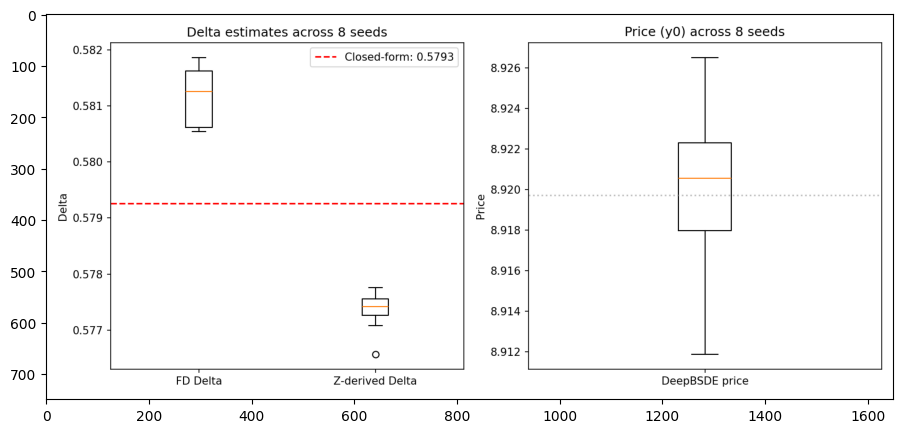

In [ ]:
#the saved plot
plt.figure(figsize=(11, 5))
plt.imshow(plt.imread('delta_price_boxplots.png'))

- #### $d > 1$ 
*here $(d = 3)$*

In [ ]:
d, N, K, T, r = 3, 20, 120.0, 1.0, 0.02
S0_base = np.array([100.0, 90.0, 120.0], dtype=np.float32)
sigma = np.array([0.2, 0.2, 0.2], dtype=np.float32)
weights = np.array([1/3, 1/3, 1/3], dtype=np.float32)
corr = np.full((d, d), 0.3, dtype=np.float32); np.fill_diagonal(corr, 1.0)
eps = 3.0

n_seeds = 8   
deltas_fd = {i: [] for i in range(d)}
deltas_z  = {i: [] for i in range(d)}
prices_base = []

for seed in range(n_seeds):
    price_base, z0_base = price_at_S0(S0_base, seed, d, N, K, weights, sigma, corr, r, T)
    prices_base.append(price_base)

    for i in range(d):
        S0_up = S0_base.copy();   S0_up[i]   += eps
        S0_down = S0_base.copy(); S0_down[i] -= eps
        price_up, _   = price_at_S0(S0_up,   seed, d, N, K, weights, sigma, corr, r, T)
        price_down, _ = price_at_S0(S0_down, seed, d, N, K, weights, sigma, corr, r, T)

        delta_fd_i = (price_up - price_down) / (2 * eps)
        delta_z_i  = z0_base[i] / (sigma[i] * S0_base[i])

        deltas_fd[i].append(delta_fd_i)
        deltas_z[i].append(delta_z_i)

    print(f"seed={seed} done  price={price_base:.4f}")

seed=0 done  price=1.6599
seed=1 done  price=1.6605
seed=2 done  price=1.6608
seed=3 done  price=1.6589
seed=4 done  price=1.6674
seed=5 done  price=1.6593
seed=6 done  price=1.6601
seed=7 done  price=1.6612


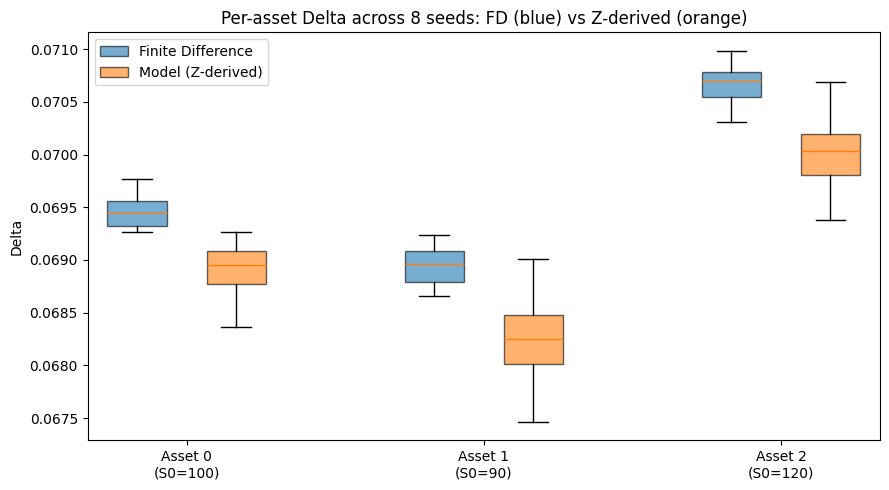

In [15]:
fig, ax = plt.subplots(figsize=(9, 5))

positions_fd = [1, 4, 7]
positions_z  = [2, 5, 8]
labels = [f'Asset {i}\n(S0={S0_base[i]:.0f})' for i in range(d)]

bp_fd = ax.boxplot([deltas_fd[i] for i in range(d)], positions=positions_fd,
                    widths=0.6, patch_artist=True,
                    boxprops=dict(facecolor='tab:blue', alpha=0.6))
bp_z  = ax.boxplot([deltas_z[i] for i in range(d)], positions=positions_z,
                    widths=0.6, patch_artist=True,
                    boxprops=dict(facecolor='tab:orange', alpha=0.6))

ax.set_xticks([1.5, 4.5, 7.5])
ax.set_xticklabels(labels)
ax.set_ylabel('Delta')
ax.set_title(f'Per-asset Delta across {n_seeds} seeds: FD (blue) vs Z-derived (orange)')
ax.legend([bp_fd["boxes"][0], bp_z["boxes"][0]], ['Finite Difference', 'Model (Z-derived)'])
plt.tight_layout()
plt.savefig('d3_delta_boxplots.png', dpi=150)
plt.show()